In [181]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt  # for making figures
%matplotlib inline

In [182]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [183]:
len(words)

32033

In [184]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [185]:
# build the dataset

block_size = 3 # take 3 characters to predict the next one
X, Y = [], [] # x is input, and y is output/label of x
for w in words[:5]:

    # print(w)
    context = [0]*block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix]
X = torch.tensor(X)
Y = torch.tensor(Y)

In [186]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [198]:
# build the dataset splits

def build_dataset(words):
    block_size = 3  # context length: how many characters do we take to predict the next one?
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [187]:
C = torch.randn((27,2))

In [188]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [189]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [190]:
h = torch.tanh(emb.view(-1,6) @ W1 + b1)

In [191]:
h

tensor([[ 0.8970, -0.9972,  0.1676,  ...,  0.9629,  1.0000,  0.9892],
        [ 0.7431, -0.7229, -0.9498,  ...,  0.9999,  0.9983,  0.8231],
        [-0.9151, -0.9952, -0.9490,  ...,  0.7363,  0.8166,  0.4782],
        ...,
        [-0.7911, -0.9810, -0.3056,  ..., -0.9864,  0.1565, -0.2282],
        [ 0.9663,  0.7978,  0.9919,  ..., -0.6248,  0.9916,  0.8984],
        [ 0.9965,  0.9913, -0.9906,  ...,  0.9966,  0.8819, -0.9772]])

In [192]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [193]:
logits = h @ W2 + b2

In [194]:
counts = logits.exp()

In [195]:
prob = counts / counts.sum(1,keepdims=True)

In [196]:
loss = -prob[torch.arange(32),Y].log().mean()
loss

tensor(21.7911)

In [295]:
# ------------ now made respectable :) ------------

Xtr.shape, Ytr.shape  # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [296]:
# initialize the model parameters
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]


In [297]:
sum(p.nelement() for p in parameters)  # number of parameters in total

17697

In [298]:
for p in parameters:
    p.requires_grad = True

In [299]:
lri = []
lossi = []
stepi = []

In [300]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

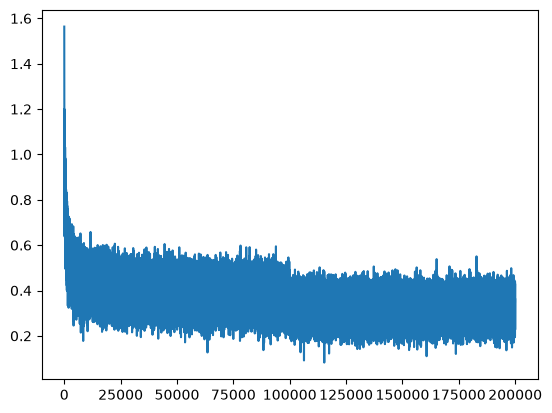

In [301]:
plt.plot(stepi, lossi)

In [302]:
# evaluate on Xdev
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1122, grad_fn=<NllLossBackward0>)

In [303]:
# evaluate on Xdev
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1757, grad_fn=<NllLossBackward0>)

In [289]:
# training : dev/validation : testing
# 80%: 10% : 10%

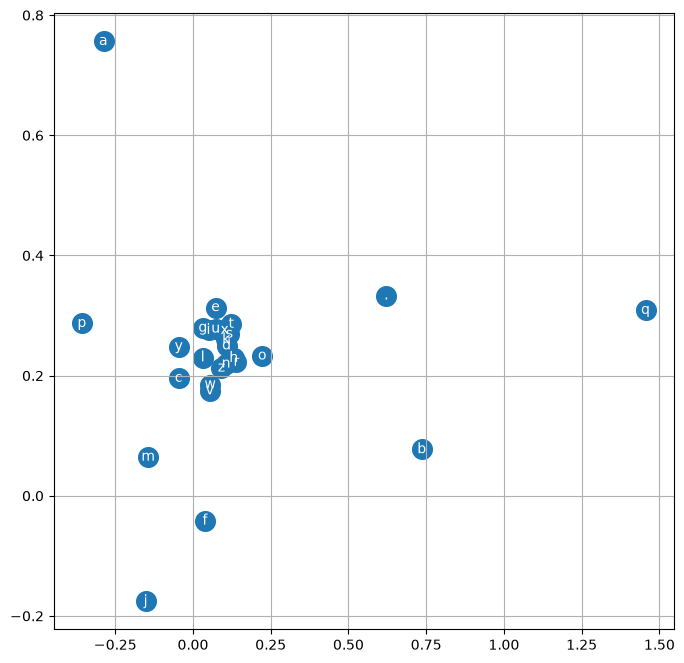

In [290]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [304]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [305]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carpavea.
jahleigh.
milia.
atlahna.
sane.
rahuel.
deliah.
jareen.
nellaritziriivon.
leigh.
ham.
joce.
quinn.
sulin.
alianni.
wanell.
dearynix.
kaellinslee.
dae.
oil.
